In [1]:
# Cell 1 - Pustaka, jalur data lokal, dan inspeksi awal metadata
import os
import glob
import numpy as np
import pandas as pd

DATA_DIR = r"C:\Users\HP\Downloads\kaggle"

train_meta_path = os.path.join(DATA_DIR, "train", "metadata.csv")
sample_sub_path = os.path.join(DATA_DIR, "sample_submission.csv")

df_meta = pd.read_csv(train_meta_path)
df_sub = pd.read_csv(sample_sub_path)

train_audio_files = glob.glob(os.path.join(DATA_DIR, "train", "audio", "*.flac"))
test_audio_files = glob.glob(os.path.join(DATA_DIR, "test", "audio", "*.flac"))

print(f"data_dir={DATA_DIR}")
print(f"train_meta_shape={df_meta.shape} | audio_files_found={len(train_audio_files)}")
print(f"sample_sub_shape={df_sub.shape} | audio_files_found={len(test_audio_files)}")
print(f"train_null_counts:\n{df_meta.isnull().sum().to_dict()}")
print(f"sample_sub_null_counts:\n{df_sub.isnull().sum().to_dict()}")
print(f"train_columns={df_meta.columns.tolist()}")
print(f"sample_sub_columns={df_sub.columns.tolist()}")


data_dir=C:\Users\HP\Downloads\kaggle
train_meta_shape=(1826, 4) | audio_files_found=1826
sample_sub_shape=(814, 2) | audio_files_found=814
train_null_counts:
{'file_id': 0, 'audio_path': 0, 'label': 0, 'source_group': 0}
sample_sub_null_counts:
{'file_id': 0, 'label': 814}
train_columns=['file_id', 'audio_path', 'label', 'source_group']
sample_sub_columns=['file_id', 'label']


Distribusi kelas data latih:
label=Bondol Jawa  | count=1124 | percentage=61.56%
label=Kutilang     | count= 619 | percentage=33.90%
label=Cendrawasih  | count=  83 | percentage= 4.55%

total_unique_source_groups=15
Struktur hierarkis source_group per label:
label=Bondol Jawa  | unique_source_groups=7
label=Cendrawasih  | unique_source_groups=4
label=Kutilang     | unique_source_groups=4
max_species_sharing_one_group=1 (100% nested jika bernilai 1)


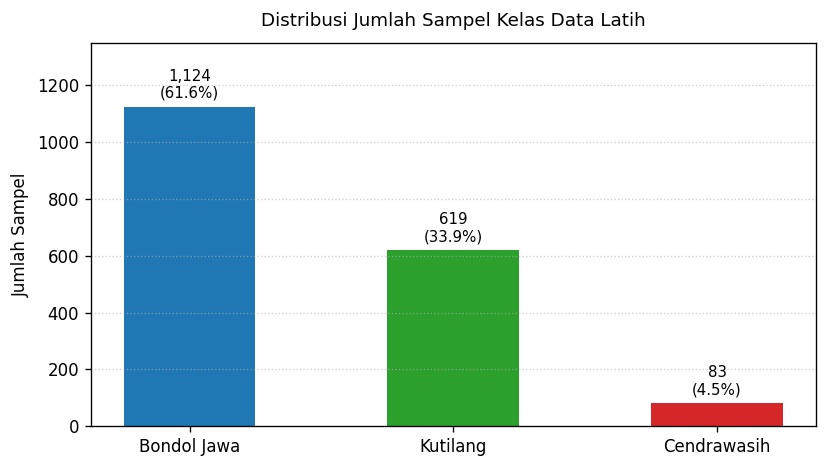

In [2]:
# Cell 2 - Distribusi kelas target dan struktur nesting source_group
import matplotlib.pyplot as plt

counts = df_meta['label'].value_counts()
pcts = df_meta['label'].value_counts(normalize=True) * 100

print("Distribusi kelas data latih:")
for lbl, cnt in counts.items():
    print(f"label={lbl:12s} | count={cnt:4d} | percentage={pcts[lbl]:5.2f}%")

# Audit keterkaitan source_group terhadap label
ct = pd.crosstab(df_meta['source_group'], df_meta['label'])
n_groups_per_label = (ct > 0).sum(axis=0)
max_species_per_group = (ct > 0).sum(axis=1).max()
total_unique_groups = df_meta['source_group'].nunique()

print(f"\ntotal_unique_source_groups={total_unique_groups}")
print("Struktur hierarkis source_group per label:")
for lbl, ng in n_groups_per_label.items():
    print(f"label={lbl:12s} | unique_source_groups={ng}")
print(f"max_species_sharing_one_group={max_species_per_group} (100% nested jika bernilai 1)")

# Visualisasi distribusi kelas
fig, ax = plt.subplots(figsize=(7, 4), dpi=120)
colors = {'Bondol Jawa': '#1f77b4', 'Kutilang': '#2ca02c', 'Cendrawasih': '#d62728'}
bar_colors = [colors.get(x, '#333333') for x in counts.index]
bars = ax.bar(counts.index, counts.values, color=bar_colors, width=0.5)

ax.set_title('Distribusi Jumlah Sampel Kelas Data Latih', fontsize=11, pad=10)
ax.set_ylabel('Jumlah Sampel', fontsize=10)
ax.grid(axis='y', linestyle=':', alpha=0.6)

for b, c, p in zip(bars, counts.values, pcts.values):
    ax.text(b.get_x() + b.get_width()/2, b.get_height() + 20, f"{c:,}\n({p:.1f}%)", 
            ha='center', va='bottom', fontsize=9)

ax.set_ylim(0, max(counts.values) * 1.2)
plt.tight_layout()
plt.show()


In [3]:
# Cell 3 - Profiling parameter audio digital dan uji drift durasi
import mutagen.flac
import soundfile as sf
from scipy import stats
from concurrent.futures import ThreadPoolExecutor

def inspect_audio_header(rel_path):
    fpath = os.path.join(DATA_DIR, rel_path)
    f = mutagen.flac.FLAC(fpath)
    sz = os.path.getsize(fpath)
    return {
        'duration': f.info.length,
        'sample_rate': f.info.sample_rate,
        'channels': f.info.channels,
        'bits_per_sample': f.info.bits_per_sample,
        'file_size_kb': sz / 1024.0
    }

# Ekstraksi header audio secara paralel
with ThreadPoolExecutor(max_workers=8) as ex:
    train_hdrs = list(ex.map(inspect_audio_header, df_meta['audio_path']))
    test_paths = [os.path.join('test', 'audio', fid + '.flac') for fid in df_sub['file_id']]
    test_hdrs = list(ex.map(inspect_audio_header, test_paths))

df_tr_hdr = pd.DataFrame(train_hdrs)
df_te_hdr = pd.DataFrame(test_hdrs)

sr_tr = df_tr_hdr['sample_rate'].unique()
sr_te = df_te_hdr['sample_rate'].unique()
bps_tr = df_tr_hdr['bits_per_sample'].unique()
bps_te = df_te_hdr['bits_per_sample'].unique()
ch_tr = df_tr_hdr['channels'].unique()
ch_te = df_te_hdr['channels'].unique()

print(f"train_sample_rates={sr_tr.tolist()} | test_sample_rates={sr_te.tolist()}")
print(f"train_bits_per_sample={bps_tr.tolist()} | test_bits_per_sample={bps_te.tolist()}")
print(f"train_channels={ch_tr.tolist()} | test_channels={ch_te.tolist()}")

tr_dur = df_tr_hdr['duration']
te_dur = df_te_hdr['duration']
ks_stat, ks_pval = stats.ks_2samp(tr_dur, te_dur)

tr_iqr = tr_dur.quantile(0.75) - tr_dur.quantile(0.25)
te_iqr = te_dur.quantile(0.75) - te_dur.quantile(0.25)

print(f"\ntrain_duration: mean={tr_dur.mean():.2f}s | std={tr_dur.std():.2f}s | median={tr_dur.median():.2f}s | iqr={tr_iqr:.2f}s | min={tr_dur.min():.2f}s | max={tr_dur.max():.2f}s")
print(f"test_duration:  mean={te_dur.mean():.2f}s | std={te_dur.std():.2f}s | median={te_dur.median():.2f}s | iqr={te_iqr:.2f}s | min={te_dur.min():.2f}s | max={te_dur.max():.2f}s")
print(f"ks_test_duration: stat={ks_stat:.4f} | p_value={ks_pval:.4f}")

train_sample_rates=[48000] | test_sample_rates=[48000]
train_bits_per_sample=[24] | test_bits_per_sample=[24]
train_channels=[2] | test_channels=[2]

train_duration: mean=10.04s | std=2.17s | median=10.03s | iqr=3.26s | min=5.27s | max=14.90s
test_duration:  mean=10.09s | std=2.10s | median=10.09s | iqr=3.08s | min=5.55s | max=14.90s
ks_test_duration: stat=0.0302 | p_value=0.6695


In [4]:
# Cell 4 - Ekstraksi fitur bioakustik DSP dan uji signifikansi spektral
import scipy.signal

def extract_dsp_record(rel_path):
    fpath = os.path.join(DATA_DIR, rel_path)
    data, sr = sf.read(fpath)
    if data.ndim == 2:
        is_stereo = bool(np.max(np.abs(data[:, 0] - data[:, 1])) > 1e-4)
        mono = np.mean(data, axis=1)
    else:
        is_stereo = False
        mono = data
        
    peak = float(np.max(np.abs(mono)))
    rms = float(np.sqrt(np.mean(mono**2)))
    zcr = float(np.mean(np.abs(np.diff(np.sign(mono)))) / 2)
    
    # Welch Power Spectral Density (jendela 2048 cuplikan)
    freqs, psd = scipy.signal.welch(mono, sr, nperseg=2048)
    psd_sum = np.sum(psd) + 1e-12
    centroid = float(np.sum(freqs * psd) / psd_sum)
    dom_freq = float(freqs[np.argmax(psd)])
    
    # Spectral rolloff (85% akumulasi energi)
    cum_psd = np.cumsum(psd)
    idx = np.searchsorted(cum_psd, 0.85 * psd_sum)
    rolloff = float(freqs[min(idx, len(freqs)-1)])
    
    # Rasio energi pita frekuensi
    low_e = float(np.sum(psd[freqs < 1000]) / psd_sum)
    mid_e = float(np.sum(psd[(freqs >= 1000) & (freqs < 4000)]) / psd_sum)
    high_e = float(np.sum(psd[freqs >= 4000]) / psd_sum)
    
    return {
        'is_stereo': is_stereo,
        'peak_amp': peak,
        'rms_energy': rms,
        'zcr': zcr,
        'spectral_centroid': centroid,
        'dominant_freq': dom_freq,
        'spectral_rolloff': rolloff,
        'low_band_energy': low_e,
        'mid_band_energy': mid_e,
        'high_band_energy': high_e
    }

cached_tr_csv = os.path.join(DATA_DIR, 'train_audio_features.csv')
if os.path.exists(cached_tr_csv):
    df_feats = pd.read_csv(cached_tr_csv)
else:
    with ThreadPoolExecutor(max_workers=8) as ex:
        feats_list = list(ex.map(extract_dsp_record, df_meta['audio_path']))
    df_feats = df_meta.copy()
    for k in feats_list[0].keys():
        df_feats[k] = [r[k] for r in feats_list]
    df_feats.to_csv(cached_tr_csv, index=False)

print("Statistik fitur akustik data latih (Median [IQR]):")
eval_features = ['mid_band_energy', 'high_band_energy', 'dominant_freq', 'spectral_rolloff']
for feat in eval_features:
    print(f"\nfeature: {feat}")
    for sp in ['Bondol Jawa', 'Cendrawasih', 'Kutilang']:
        sub = df_feats[df_feats['label'] == sp][feat]
        med = sub.median()
        iqr = sub.quantile(0.75) - sub.quantile(0.25)
        print(f"  label={sp:12s} | median={med:10.4f} | iqr={iqr:10.4f}")
    groups = [df_feats[df_feats['label'] == sp][feat].values for sp in ['Bondol Jawa', 'Cendrawasih', 'Kutilang']]
    h_stat, p_val = stats.kruskal(*groups)
    print(f"  kruskal_wallis: H={h_stat:8.2f} | p_value={p_val:.3e}")

Statistik fitur akustik data latih (Median [IQR]):

feature: mid_band_energy
  label=Bondol Jawa  | median=    0.3761 | iqr=    0.2792
  label=Cendrawasih  | median=    0.4291 | iqr=    0.2856
  label=Kutilang     | median=    0.6405 | iqr=    0.2452
  kruskal_wallis: H=  455.45 | p_value=1.260e-99

feature: high_band_energy
  label=Bondol Jawa  | median=    0.4196 | iqr=    0.3158
  label=Cendrawasih  | median=    0.3228 | iqr=    0.3652
  label=Kutilang     | median=    0.1830 | iqr=    0.2014
  kruskal_wallis: H=  391.45 | p_value=9.938e-86

feature: dominant_freq
  label=Bondol Jawa  | median= 3679.6875 | iqr= 1265.6250
  label=Cendrawasih  | median= 1992.1875 | iqr= 1652.3438
  label=Kutilang     | median= 2859.3750 | iqr= 2296.8750
  kruskal_wallis: H=  191.14 | p_value=3.115e-42

feature: spectral_rolloff
  label=Bondol Jawa  | median= 4945.3125 | iqr= 1716.7969
  label=Cendrawasih  | median= 6093.7500 | iqr= 2167.9688
  label=Kutilang     | median= 4289.0625 | iqr= 2437.5000
  

In [5]:
# Cell 5 - Audit varians klaster source_group dan simulasi StratifiedGroupKFold
from sklearn.model_selection import StratifiedGroupKFold

print("Varians internal yang dijelaskan oleh source_group (Eta-squared):")
for sp in ['Bondol Jawa', 'Cendrawasih', 'Kutilang']:
    sub = df_feats[df_feats['label'] == sp]
    groups = [grp['mid_band_energy'].values for _, grp in sub.groupby('source_group')]
    if len(groups) > 1:
        h_stat, p_val = stats.kruskal(*groups)
        n = len(sub)
        k = len(groups)
        # Estimasi effect size Eta-squared dari H-stat
        eta_sq = max(0, (h_stat - k + 1) / (n - k))
        print(f"species={sp:12s} | n_groups={k:2d} | H={h_stat:8.2f} | p_value={p_val:.3e} | eta_squared={eta_sq:.4f}")

# Pengujian skema 4-Fold Stratified Group K-Fold
sgkf = StratifiedGroupKFold(n_splits=4)
print("\nVerifikasi distribusi fold pada 4-Fold Stratified Group K-Fold:")
for fold, (trn_idx, val_idx) in enumerate(sgkf.split(df_feats, df_feats['label'], df_feats['source_group'])):
    val_df = df_feats.iloc[val_idx]
    val_labels = val_df['label'].value_counts().to_dict()
    val_groups = val_df['source_group'].nunique()
    print(f"fold={fold+1}/4 | val_samples={len(val_idx):3d} | unique_groups={val_groups:2d} | class_dist={val_labels}")


Varians internal yang dijelaskan oleh source_group (Eta-squared):
species=Bondol Jawa  | n_groups= 7 | H=  270.32 | p_value=1.855e-55 | eta_squared=0.2366
species=Cendrawasih  | n_groups= 4 | H=    2.70 | p_value=4.396e-01 | eta_squared=0.0000
species=Kutilang     | n_groups= 4 | H=   27.36 | p_value=4.942e-06 | eta_squared=0.0396

Verifikasi distribusi fold pada 4-Fold Stratified Group K-Fold:
fold=1/4 | val_samples=471 | unique_groups= 3 | class_dist={'Bondol Jawa': 336, 'Kutilang': 132, 'Cendrawasih': 3}
fold=2/4 | val_samples=449 | unique_groups= 4 | class_dist={'Bondol Jawa': 290, 'Kutilang': 143, 'Cendrawasih': 16}
fold=3/4 | val_samples=453 | unique_groups= 4 | class_dist={'Bondol Jawa': 240, 'Kutilang': 178, 'Cendrawasih': 35}
fold=4/4 | val_samples=453 | unique_groups= 4 | class_dist={'Bondol Jawa': 258, 'Kutilang': 166, 'Cendrawasih': 29}


In [6]:
# Cell 6 - Ekstraksi fitur data uji dan deteksi Out-of-Distribution (kandidat Unknown)
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors

cached_te_csv = os.path.join(DATA_DIR, 'test_audio_features.csv')
if os.path.exists(cached_te_csv):
    df_te_feats = pd.read_csv(cached_te_csv)
else:
    with ThreadPoolExecutor(max_workers=8) as ex:
        test_paths = [os.path.join('test', 'audio', fid + '.flac') for fid in df_sub['file_id']]
        feats_te_list = list(ex.map(extract_dsp_record, test_paths))
    df_te_feats = pd.DataFrame(feats_te_list)
    df_te_feats['file_id'] = df_sub['file_id']
    df_te_feats.to_csv(cached_te_csv, index=False)

feature_cols = [
    'rms_energy', 'zcr', 'spectral_centroid', 
    'dominant_freq', 'spectral_rolloff', 
    'low_band_energy', 'mid_band_energy', 'high_band_energy'
]

scaler = StandardScaler()
X_tr = scaler.fit_transform(df_feats[feature_cols])
X_te = scaler.transform(df_te_feats[feature_cols])

# Hitung jarak k-NN (k=5) ke manifold data latih
nn = NearestNeighbors(n_neighbors=5).fit(X_tr)
tr_dists, _ = nn.kneighbors(X_tr)
te_dists, _ = nn.kneighbors(X_te)

tr_mean_dist = tr_dists[:, 1:].mean(axis=1) # abaikan jarak ke diri sendiri
te_mean_dist = te_dists.mean(axis=1)

p95_dist = np.percentile(tr_mean_dist, 95)
p99_dist = np.percentile(tr_mean_dist, 99)

is_ood = te_mean_dist > p95_dist
df_te_feats['is_ood'] = is_ood

print(f"train_mean_knn_dist={tr_mean_dist.mean():.4f} | p95_threshold={p95_dist:.4f} | p99_threshold={p99_dist:.4f}")
print(f"test_mean_knn_dist={te_mean_dist.mean():.4f}")
print(f"test_samples_exceeding_p95={is_ood.sum()} / {len(is_ood)} ({is_ood.mean()*100:.2f}%)")
print(f"test_samples_exceeding_p99={(te_mean_dist > p99_dist).sum()} / {len(te_mean_dist)} ({(te_mean_dist > p99_dist).mean()*100:.2f}%)")

print("\nPerbandingan fitur In-Distribution Test vs Kandidat Unknown (Median):")
for col in ['dominant_freq', 'low_band_energy', 'mid_band_energy', 'high_band_energy', 'rms_energy']:
    med_in = df_te_feats[~df_te_feats['is_ood']][col].median()
    med_ood = df_te_feats[df_te_feats['is_ood']][col].median()
    print(f"feature={col:18s} | in_dist={med_in:10.4f} | candidate_unknown={med_ood:10.4f}")

train_mean_knn_dist=0.6201 | p95_threshold=1.0235 | p99_threshold=1.3432
test_mean_knn_dist=0.7496
test_samples_exceeding_p95=116 / 814 (14.25%)
test_samples_exceeding_p99=48 / 814 (5.90%)

Perbandingan fitur In-Distribution Test vs Kandidat Unknown (Median):
feature=dominant_freq      | in_dist= 2929.6875 | candidate_unknown= 1359.3750
feature=low_band_energy    | in_dist=    0.1064 | candidate_unknown=    0.1933
feature=mid_band_energy    | in_dist=    0.5280 | candidate_unknown=    0.2520
feature=high_band_energy   | in_dist=    0.2608 | candidate_unknown=    0.4591
feature=rms_energy         | in_dist=    0.0882 | candidate_unknown=    0.0812


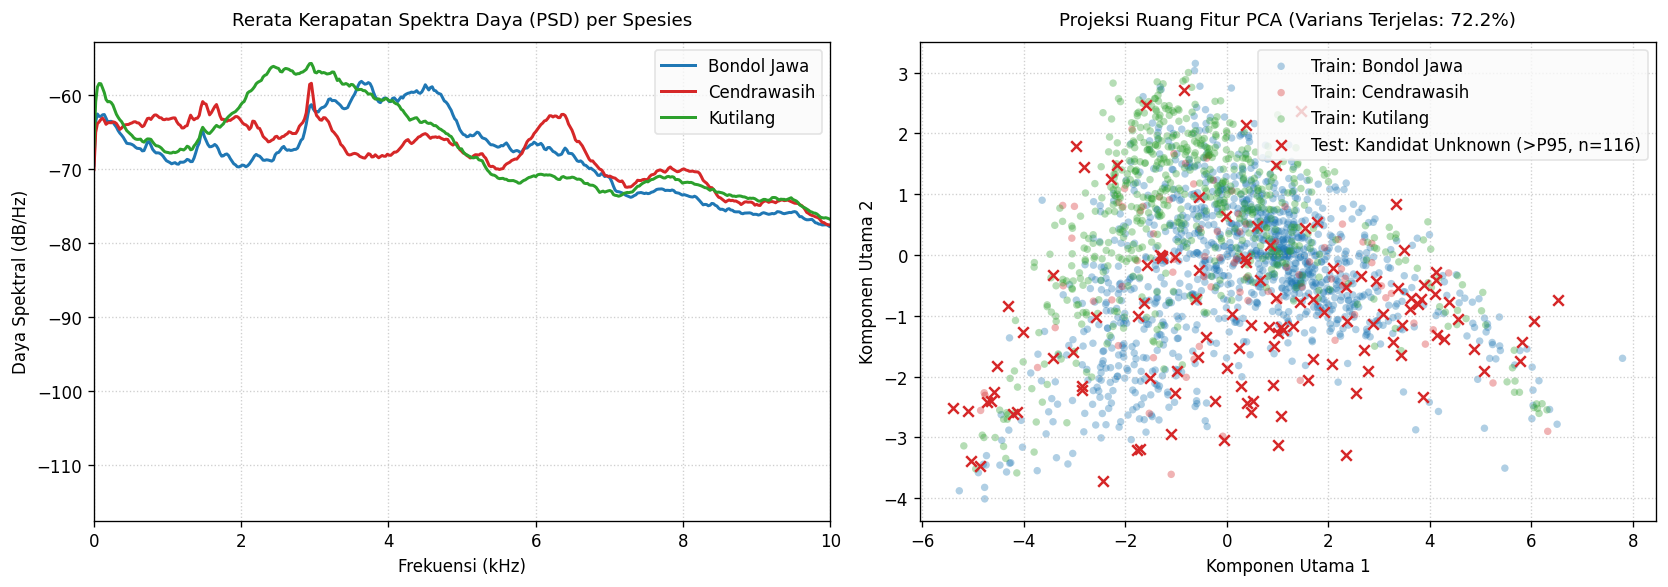

pca_explained_variance_ratio: PC1=51.85% | PC2=20.33%
total_visualized_unknown_candidates=116


In [7]:
# Cell 7 - Visualisasi kurva Welch PSD dan projeksi ruang fitur PCA
from sklearn.decomposition import PCA

species_list = ['Bondol Jawa', 'Cendrawasih', 'Kutilang']
colors = {'Bondol Jawa': '#1f77b4', 'Cendrawasih': '#d62728', 'Kutilang': '#2ca02c'}

fig, axes = plt.subplots(1, 2, figsize=(14, 5), dpi=120)

# Panel 1: Kurva Rerata Welch PSD per Spesies
ax1 = axes[0]
for sp in species_list:
    sample_sub = df_feats[df_feats['label'] == sp]['audio_path'].head(35)
    psds = []
    for p in sample_sub:
        d, sr = sf.read(os.path.join(DATA_DIR, p))
        m = np.mean(d, axis=1) if d.ndim == 2 else d
        f, pxx = scipy.signal.welch(m, sr, nperseg=2048)
        psds.append(10 * np.log10(pxx + 1e-12))
    ax1.plot(f / 1000.0, np.mean(psds, axis=0), label=sp, color=colors[sp], linewidth=1.8)

ax1.set_xlim(0, 10)
ax1.set_title('Rerata Kerapatan Spektra Daya (PSD) per Spesies', fontsize=11, pad=10)
ax1.set_xlabel('Frekuensi (kHz)', fontsize=10)
ax1.set_ylabel('Daya Spektral (dB/Hz)', fontsize=10)
ax1.legend(frameon=True, facecolor='#fafafa', edgecolor='#dddddd')
ax1.grid(True, linestyle=':', alpha=0.6)

# Panel 2: Projeksi PCA Fitur Akustik (Train vs Test Unknown)
pca = PCA(n_components=2, random_state=42)
X_tr_pca = pca.fit_transform(X_tr)
X_te_pca = pca.transform(X_te)

ax2 = axes[1]
for sp in species_list:
    m = df_feats['label'] == sp
    ax2.scatter(X_tr_pca[m, 0], X_tr_pca[m, 1], c=colors[sp], label=f"Train: {sp}", alpha=0.35, s=20, edgecolors='none')

ax2.scatter(X_te_pca[is_ood, 0], X_te_pca[is_ood, 1], c='#d62728', marker='x', s=40, linewidths=1.5,
            label=f"Test: Kandidat Unknown (>P95, n={is_ood.sum()})", zorder=5)

var_exp = pca.explained_variance_ratio_.sum() * 100
ax2.set_title(f'Projeksi Ruang Fitur PCA (Varians Terjelas: {var_exp:.1f}%)', fontsize=11, pad=10)
ax2.set_xlabel('Komponen Utama 1', fontsize=10)
ax2.set_ylabel('Komponen Utama 2', fontsize=10)
ax2.legend(frameon=True, facecolor='#fafafa', edgecolor='#dddddd')
ax2.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

print(f"pca_explained_variance_ratio: PC1={pca.explained_variance_ratio_[0]*100:.2f}% | PC2={pca.explained_variance_ratio_[1]*100:.2f}%")
print(f"total_visualized_unknown_candidates={is_ood.sum()}")